# 04 – Where is the charging gap?

**Business question 2.** Which local authorities have the most EVs per public charger?

**Two important choices**

1. **Privately kept battery electric cars are used for the local comparison.** Company cars are registered at the company's address, not where the driver lives. Lease companies are concentrated in a few places, so totals give nonsense results there (e.g. Windsor and Maidenhead has 200,000 battery electric cars, 98% company owned). Private cars show where EV drivers actually live. Because company cars (about half of all battery electric cars) are left out, the ratio is best read as a **relative measure for comparing areas**, not as the true number of cars per charger.
2. **Chargers vs devices.** The local comparison uses *chargers* (EVCI0102, 1 July 2026), matched with vehicles at 30 June 2026. The national trend uses *devices* (EVCI9001), the only series that goes back to 2019. The two are never mixed.

**Caveat: home charging.** Drivers with a driveway or garage mostly charge at home. A high ratio in a suburban area with many driveways is less urgent than the same ratio in a city of flats and terraced streets. Off-street parking is not in this dataset, so this is kept in mind when interpreting the results and in question 4.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

PROCESSED = "../data/processed/"
FIGURES = "../outputs/figures/"

# Chart style: light surface, quiet grid and axes, 2px lines
SURFACE, TEXT, TEXT_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": TEXT, "axes.labelcolor": TEXT_2,
    "xtick.color": TEXT_2, "ytick.color": TEXT_2,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 1,
    "lines.linewidth": 2, "lines.solid_capstyle": "round",
    "axes.titlesize": 13, "axes.titleweight": "semibold", "axes.titlelocation": "left",
})


def add_source(fig, text):
    fig.text(0.01, 0.01, text, fontsize=8, color=TEXT_2)

## 1. National trend: is charging keeping pace?

Battery electric cars (all keepers) per public charging device, every quarter since October 2019. Devices are counted on the first day of a quarter, so they are matched with vehicles on the last day of the previous quarter (e.g. devices on 1 October with cars on 30 September).

If the line rises, EVs are growing faster than public charging.

In [2]:
vehicles = pd.read_csv(PROCESSED + "vehicles_by_la.csv", parse_dates=["quarter_end"])
devices_uk = pd.read_csv(PROCESSED + "charging_devices_uk_history.csv", parse_dates=["quarter_start"])

cars = vehicles[vehicles["body_type"] == "Cars"]
uk_cars = cars.groupby("quarter_end", as_index=False)[["bev", "bev_private"]].sum()
# Match vehicles on 30 September with devices on 1 October, and so on
uk_cars["quarter_start"] = uk_cars["quarter_end"] + pd.Timedelta(days=1)

trend = devices_uk.merge(uk_cars, on="quarter_start")
trend["bev_per_device"] = trend["bev"] / trend["devices"]
trend[["quarter_start", "devices", "bev", "bev_per_device"]].iloc[[0, 4, 8, 12, 16, 20, 24, -1]].round(1)

,quarter_start,devices,bev,bev_per_device
0,2019-10-01,15116,77555.0,5.1
4,2020-10-01,19487,152498.0,7.8
8,2021-10-01,25927,311063.0,12.0
12,2022-10-01,34637,538758.0,15.6
16,2023-10-01,49220,850291.0,17.3
20,2024-10-01,70042,1169704.0,16.7
24,2025-10-01,86021,1599368.0,18.6
27,2026-07-01,94595,1977019.0,20.9


In [3]:
first, last = trend.iloc[0], trend.iloc[-1]
print(f"Public devices: {first['devices']:,.0f} -> {last['devices']:,.0f} ({last['devices'] / first['devices']:.1f}x)")
print(f"Battery electric cars: {first['bev']:,.0f} -> {last['bev']:,.0f} ({last['bev'] / first['bev']:.1f}x)")

Public devices: 15,116 -> 94,595 (6.3x)
Battery electric cars: 77,555 -> 1,977,019 (25.5x)


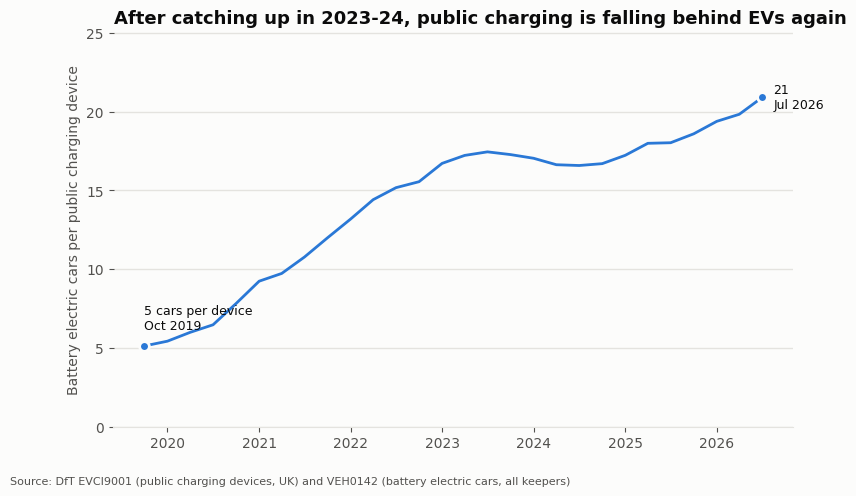

In [4]:
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.plot(trend["quarter_start"], trend["bev_per_device"], color=BLUE)
for _, row in trend.iloc[[0, -1]].iterrows():
    ax.plot(row["quarter_start"], row["bev_per_device"], "o", color=BLUE, markersize=7,
            markeredgecolor=SURFACE, markeredgewidth=2)
ax.annotate(f"{first['bev_per_device']:.0f} cars per device\nOct 2019", (first["quarter_start"], first["bev_per_device"]),
            xytext=(0, 12), textcoords="offset points", fontsize=9, color=TEXT)
ax.annotate(f"{last['bev_per_device']:.0f}\nJul 2026", (last["quarter_start"], last["bev_per_device"]),
            xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=TEXT)

ax.set_title("After catching up in 2023-24, public charging is falling behind EVs again")
ax.set_ylabel("Battery electric cars per public charging device")
ax.set_ylim(0, trend["bev_per_device"].max() * 1.2)
plt.subplots_adjust(right=0.88, bottom=0.12)
add_source(fig, "Source: DfT EVCI9001 (public charging devices, UK) and VEH0142 (battery electric cars, all keepers)")
fig.savefig(FIGURES + "04_bev_per_charging_device_uk.png", dpi=200)
plt.show()

**How to read this chart:** each point is the number of battery electric cars on the road for every public charging device in the UK.

**What it shows:** the story has three phases.
- **2019 to mid-2023: EVs raced ahead.** Cars per device rose from 5 to 17, because battery electric cars grew 25-fold while devices grew 6-fold over the whole period.
- **Mid-2023 to end of 2024: charging caught up.** The ratio stayed flat at about 17 as charger roll-out accelerated.
- **Since 2025: the gap is opening again.** The ratio rose from 17 to 21. In the last year, devices grew about 15% while battery electric cars grew 34%.

Part of the last step (April to July 2026) is due to about 1,270 private chargers being removed from the data, but the upward trend started well before that.

## 2. Local analysis table, July 2026

One row per local authority, combining private battery electric cars (30 June 2026), public chargers (1 July 2026) and population (2024). The table is saved so questions 3 and 4 can reuse it.

In [5]:
latest_cars = cars[cars["quarter"] == "2026 Q2"][["la_code", "la_name", "bev", "bev_private", "all_vehicles_private"]]
chargers = pd.read_csv(PROCESSED + "chargers_by_la.csv")
chargers_jul = chargers[chargers["snapshot_date"] == "2026-07-01"][["la_code", "chargers", "chargers_50kw_plus"]]
income_population = pd.read_csv(PROCESSED + "income_population_by_la.csv")

la = (
    latest_cars
    .merge(chargers_jul, on="la_code")
    .merge(income_population[["la_code", "region", "population_2024", "gdhi_per_head_2024"]], on="la_code")
)
la["bev_private_per_charger"] = la["bev_private"] / la["chargers"]
la["chargers_per_100k"] = la["chargers"] / la["population_2024"] * 100_000
la["bev_private_share"] = la["bev_private"] / la["all_vehicles_private"] * 100

print(la.shape)
la.to_csv(PROCESSED + "la_analysis_table.csv", index=False)
la[["bev_private_per_charger", "chargers_per_100k", "bev_private_share"]].describe().round(1)

(361, 13)


,bev_private_per_charger,chargers_per_100k,bev_private_share
count,361.0,361.0,361.0
mean,11.4,176.9,3.1
std,6.6,148.7,1.0
min,0.4,37.5,0.7
25%,6.8,100.1,2.6
50%,10.7,139.0,3.1
75%,14.9,197.8,3.7
max,50.3,1379.5,7.8


In [6]:
uk_ratio = la["bev_private"].sum() / la["chargers"].sum()
print(f"UK: {uk_ratio:.1f} private battery electric cars per public charger")
print(f"Typical local authority (median): {la['bev_private_per_charger'].median():.1f}")

UK: 7.9 private battery electric cars per public charger
Typical local authority (median): 10.7


The UK figure (about 8) is lower than the typical local authority (about 11) because London has many chargers and relatively few private EVs, which pulls the UK total down.

## 3. By region

In [7]:
region = la.groupby("region")[["bev_private", "chargers"]].sum()
region["bev_private_per_charger"] = region["bev_private"] / region["chargers"]
region = region.sort_values("bev_private_per_charger")
region.round(1)

,bev_private,chargers,bev_private_per_charger
region,,,
London,93508.0,31371,3.0
Scotland,79013.0,12847,6.2
Wales,37088.0,5910,6.3
West Midlands,80862.0,10143,8.0
North East,35121.0,4147,8.5
South West,86079.0,9232,9.3
East of England,103606.0,9880,10.5
South East,167271.0,15373,10.9
Northern Ireland,13365.0,1156,11.6


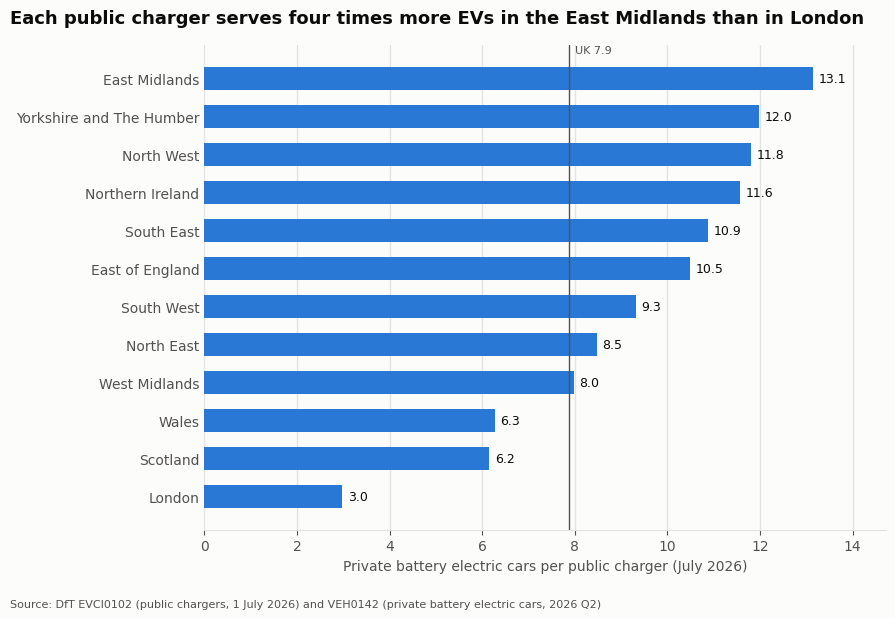

In [8]:
def bar_chart(data, labels, title, xlabel, filename, source, reference=None):
    fig, ax = plt.subplots(figsize=(9, 0.38 * len(data) + 1.6))
    y = range(len(data))
    ax.barh(y, data, height=0.6, color=BLUE)
    ax.set_yticks(list(y))
    ax.set_yticklabels(labels)
    for i, value in enumerate(data):
        ax.annotate(f"{value:.1f}", (value, i), xytext=(4, 0), textcoords="offset points",
                    va="center", fontsize=9, color=TEXT)
    if reference is not None:
        value, text = reference
        ax.axvline(value, color=TEXT_2, linewidth=1)
        ax.annotate(text, (value, len(data) - 0.4), xytext=(4, 0), textcoords="offset points",
                    fontsize=8, color=TEXT_2, va="bottom")
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0)
    ax.set_xlim(0, max(data) * 1.12)
    # Title aligned to the left edge of the figure, so long bar labels do not push it off the page
    fig.suptitle(title, x=0.01, ha="left", fontsize=13, fontweight="semibold")
    ax.set_xlabel(xlabel)
    plt.tight_layout(rect=(0, 0.04, 1, 1))
    add_source(fig, source)
    fig.savefig(FIGURES + filename, dpi=200)
    plt.show()


bar_chart(
    region["bev_private_per_charger"], region.index,
    "Each public charger serves four times more EVs in the East Midlands than in London",
    "Private battery electric cars per public charger (July 2026)",
    "05_bev_per_charger_by_region.png",
    "Source: DfT EVCI0102 (public chargers, 1 July 2026) and VEH0142 (private battery electric cars, 2026 Q2)",
    reference=(uk_ratio, f"UK {uk_ratio:.1f}"),
)

**How to read this chart:** each bar is the number of privately kept battery electric cars for every public charger in the region. A longer bar means each charger has more local EVs to serve, i.e. a bigger gap. The grey line is the UK figure.

**What it shows**
- **London has by far the most public charging per EV (3 cars per charger).** This is expected: most Londoners have no driveway, and London boroughs have installed many on-street chargers.
- **The East Midlands (13.1), Yorkshire and the Humber (12.0), the North West (11.8) and Northern Ireland (11.6) have the biggest gaps**, roughly four times London's level.
- Scotland and Wales sit close to each other at about 6, well below the English regions outside London.

## 4. Local authorities with the biggest gaps

In [9]:
top = la.sort_values("bev_private_per_charger", ascending=False).head(15)
top[["la_name", "region", "bev_private", "chargers", "chargers_50kw_plus", "bev_private_per_charger", "chargers_per_100k"]].round(1)

,la_name,region,bev_private,chargers,chargers_50kw_plus,bev_private_per_charger,chargers_per_100k
74,North East Derbyshire,East Midlands,2012.0,40,7,50.3,37.5
226,Fareham,South East,2444.0,71,28,34.4,61.5
80,Melton,East Midlands,1124.0,34,6,33.1,62.9
103,Lichfield,West Midlands,2587.0,84,36,30.8,75.0
146,Maldon,East of England,1225.0,42,17,29.2,60.8
224,East Hampshire,South East,3156.0,109,49,29.0,83.9
329,East Renfrewshire,Scotland,2330.0,82,26,28.4,82.1
89,West Lindsey,East Midlands,1951.0,69,34,28.3,69.6
141,Castle Point,East of England,1049.0,38,26,27.6,42.0
68,Amber Valley,East Midlands,2458.0,98,30,25.1,75.1


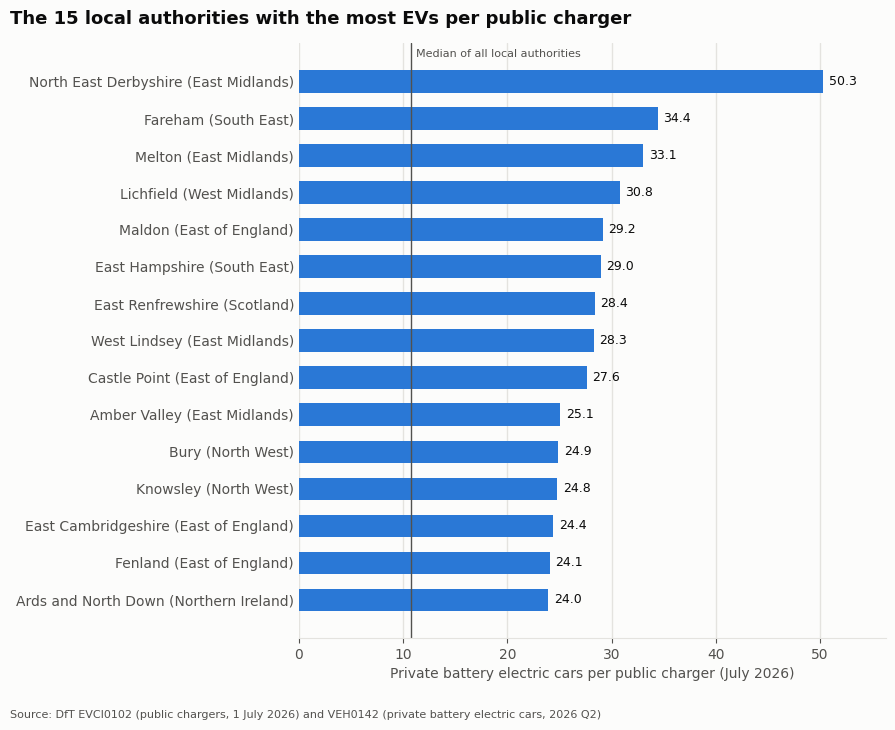

In [10]:
top_sorted = top.sort_values("bev_private_per_charger")
bar_chart(
    top_sorted["bev_private_per_charger"],
    top_sorted["la_name"] + " (" + top_sorted["region"] + ")",
    "The 15 local authorities with the most EVs per public charger",
    "Private battery electric cars per public charger (July 2026)",
    "06_top15_bev_per_charger_la.png",
    "Source: DfT EVCI0102 (public chargers, 1 July 2026) and VEH0142 (private battery electric cars, 2026 Q2)",
    reference=(la["bev_private_per_charger"].median(), "Median of all local authorities"),
)

In [11]:
# At the other end: the local authorities with the fewest EVs per charger
la.sort_values("bev_private_per_charger").head(10)[["la_name", "region", "bev_private", "chargers", "bev_private_per_charger"]].round(1)

,la_name,region,bev_private,chargers,bev_private_per_charger
274,Isles of Scilly,South West,7.0,16,0.4
183,Tower Hamlets,London,1595.0,2574,0.6
174,Hackney,London,1257.0,1701,0.7
175,Hammersmith and Fulham,London,1952.0,2603,0.7
185,Westminster,London,2901.0,2893,1.0
204,Waltham Forest,London,1974.0,1855,1.1
182,Southwark,London,2202.0,1945,1.1
115,Coventry,West Midlands,3016.0,2644,1.1
337,Na h-Eileanan Siar,Scotland,177.0,134,1.3
173,City of London,London,93.0,67,1.4


**How to read this chart:** the same measure as above, for the 15 local authorities with the highest values. The grey line is the median of all 361 local authorities.

**What it shows**
- The biggest gaps are mostly in **suburban and semi-rural districts in the Midlands, the South East and the East of England** (e.g. North East Derbyshire, Fareham, Melton, Lichfield). Each has 2–5 times the typical number of EVs per charger.
- The smallest gaps are almost all **inner London boroughs** (Tower Hamlets, Hackney, Hammersmith and Fulham, Westminster), with about one private EV per charger or fewer, plus Coventry, which also has a very large number of public chargers for its size.

**Interpretation, with the home charging caveat:** many of the top 15 are areas of detached and semi-detached houses where most EV owners can charge on their own driveway. Their high ratio partly reflects lower *need* for public charging, not only a lack of it. These areas still matter for **rapid charging** (for longer journeys and for drivers without driveways), and the gap will grow as EV ownership spreads to households without off-street parking. Question 4 combines this ratio with other factors before recommending where to invest.

## Answer to question 2

- **Nationally, EVs have outgrown public charging since 2019.** Charging caught up in 2023–2024, but **the gap has been opening again since 2025**, as charger growth slowed while EV growth did not.
- **The gap is regional:** private EVs per charger are about four times higher in the East Midlands, Yorkshire and the Humber and the North West than in London.
- **Locally, the biggest gaps are in suburban and semi-rural districts outside London**, led by North East Derbyshire, Fareham and Melton. Some of this is offset by home charging, so these areas are candidates for investment but not automatically the top priority.